# BrainScan-V2 : Partie 1, Classification des tumeurs cérébrales (GoogLeNet)

Pipeline de préparation des données : validation, doublons, exploration, split 70/15/15, augmentation, `tf.data`.
Le notebook est ré-exécutable de haut en bas (le dossier `data/split` est recréé à chaque exécution).

In [ ]:
import random
import shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

IMG_SIZE = 224
IMG_EXT = ('.png', '.jpeg', '.jpg', '.bmp')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent            
DATA_DIR = ROOT / 'data'
SPLIT_DIR = DATA_DIR / 'split'      

# official dataset folders 
SOURCE_NAMES = {'train', 'val'}
SOURCE_DIRS = sorted(d for d in DATA_DIR.iterdir() if d.is_dir() and d.name.lower() in SOURCE_NAMES)
assert SOURCE_DIRS, f"No Train/Val folder found in {DATA_DIR}"

print('Project root :', ROOT)
print('Source folders:', [d.name for d in SOURCE_DIRS])

Project root : c:\BrainScan_V2
Source folders: ['Train', 'Val']


## 1. Chargement et prétraitement du dataset
### 1.1 Chargement et contrôle qualité


In [2]:
def normalize_label(name):
    return name.strip().lower().replace(' ', '_')


def check_image(path):
    try:
        with Image.open(path) as im:
            im.verify()              # detects most corruption
        with Image.open(path) as im:  # verify() invalidates the file, so reopen
            im.load()                
            w, h = im.size
        return True, '', w, h
    except Exception as e:
        return False, f'corrupted: {e}', None, None


records = []
for source_dir in SOURCE_DIRS:
    for class_dir in sorted(p for p in source_dir.iterdir() if p.is_dir()):
        label = normalize_label(class_dir.name)

        images_dir = class_dir / 'images'          # this dataset: images/ and labels/
        if not images_dir.is_dir():
            images_dir = class_dir                 # fallback: images directly in the class folder

        for file in images_dir.iterdir():          # was: class_dir.iterdir()
            if not file.is_file():
                continue
            row = dict(path=str(file), label=label, source=source_dir.name)
            if file.suffix.lower() not in IMG_EXT:
                row.update(ok=False, reason='bad extension', w=None, h=None)
            else:
                ok, reason, w, h = check_image(file)
                row.update(ok=ok, reason=reason, w=w, h=h)
            records.append(row)

all_df = pd.DataFrame(records)
files_df = all_df[all_df['ok']].drop(columns=['ok', 'reason']).reset_index(drop=True)
files_df[['w', 'h']] = files_df[['w', 'h']].astype(int)
invalid_df = all_df[~all_df['ok']]

print(f"Valid images:   {len(files_df)}")
print(f"Invalid images: {len(invalid_df)}  (discarded)")
if len(invalid_df):
    display(invalid_df[['path', 'reason']])
print()
print(files_df.groupby(['source', 'label']).size().unstack())

Valid images:   5249
Invalid images: 0  (discarded)

label   glioma  meningioma  no_tumor  pituitary
source                                         
Train     1153        1449       711       1424
Val        136         140       100        136


### 1.2 Détection des doublons

In [3]:
HASH_SIZE = 16    
MAX_DIST = 6     

def dhash(path, size=HASH_SIZE):
    with Image.open(path) as im:
        g = im.convert('L').resize((size + 1, size))
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()         


df = files_df.copy()
hashes = np.stack([dhash(p) for p in df['path']]).astype(np.float32)   
inv = 1 - hashes
n = len(df)

# number of differing bits between every pair 
pairs = []
for start in range(0, n, 1000):
    stop = min(start + 1000, n)
    dist = hashes[start:stop] @ inv.T + inv[start:stop] @ hashes.T
    later = np.arange(n)[None, :] > np.arange(start, stop)[:, None]    # only count each pair once
    rows, cols = np.where((dist <= MAX_DIST) & later)
    pairs += [(start + r, c, int(dist[r, c])) for r, c in zip(rows, cols)]

pairs_df = pd.DataFrame(pairs, columns=['i', 'j', 'dist'])
labels = df['label'].values
sources = df['source'].values

# same image under two different classes = ambiguous -> drop every copy
conflict = {int(k) for i, j in zip(pairs_df['i'], pairs_df['j']) if labels[i] != labels[j] for k in (i, j)}
# otherwise keep the first image of each group, drop the later copies
copies = {int(j) for j in pairs_df['j']}
drop_idx = sorted(copies | conflict)

cross_source = sum(sources[i] != sources[j] for i, j in zip(pairs_df['i'], pairs_df['j']))
print(f"Duplicate pairs found      : {len(pairs_df)}")
print(f"  exact (0 bit difference) : {(pairs_df['dist'] == 0).sum()}")
print(f"  near-identical           : {(pairs_df['dist'] > 0).sum()}")
print(f"  across Train/Val folders : {cross_source}   <- leakage in the official split")
print(f"Same image, different label: {len(conflict)} images")
print(f"Images to drop             : {len(drop_idx)} / {n}")

Duplicate pairs found      : 2300
  exact (0 bit difference) : 1635
  near-identical           : 665
  across Train/Val folders : 360   <- leakage in the official split
Same image, different label: 0 images
Images to drop             : 1535 / 5249


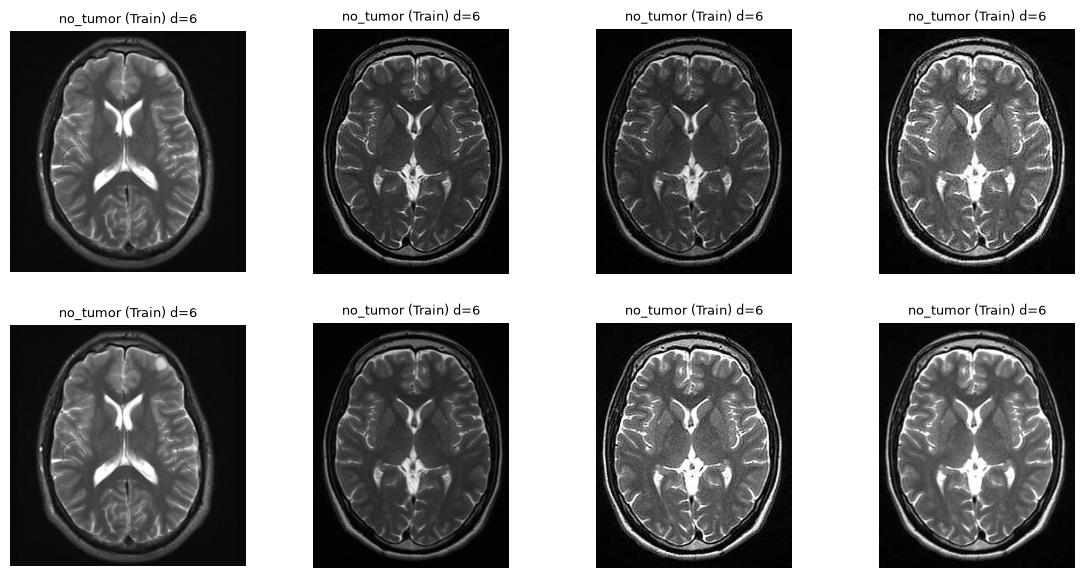

In [4]:
# visual check: the most doubtful pairs to validate MAX_DIST
if len(pairs_df):
    show = pairs_df.sort_values('dist', ascending=False).head(4)
    fig, axes = plt.subplots(2, len(show), figsize=(3.5 * len(show), 7), squeeze=False)
    for col, (_, r) in enumerate(show.iterrows()):
        for row, idx in enumerate((int(r['i']), int(r['j']))):
            axes[row, col].imshow(Image.open(df['path'][idx]), cmap='gray')
            axes[row, col].set_title(f"{df['label'][idx]} ({df['source'][idx]}) d={int(r['dist'])}", fontsize=9)
            axes[row, col].axis('off')
    plt.show()
else:
    print('No duplicates found')

In [5]:
before = len(df)
df = df.drop(index=drop_idx).reset_index(drop=True)
print(f"Images: {before} -> {len(df)}  ({before - len(df)} removed)")

Images: 5249 -> 3714  (1535 removed)


### 1.3 Exploration des classes

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
label
glioma        1190
meningioma    1087
pituitary     1026
no_tumor       411
Name: count, dtype: int64


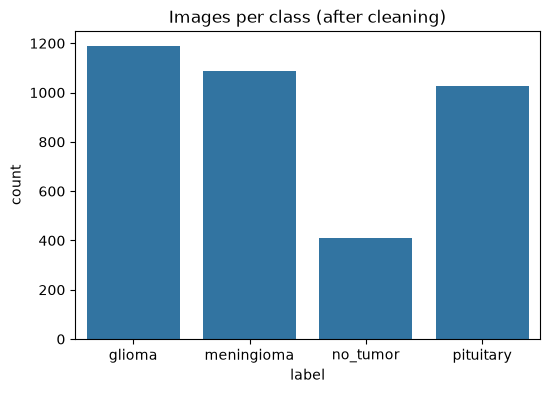

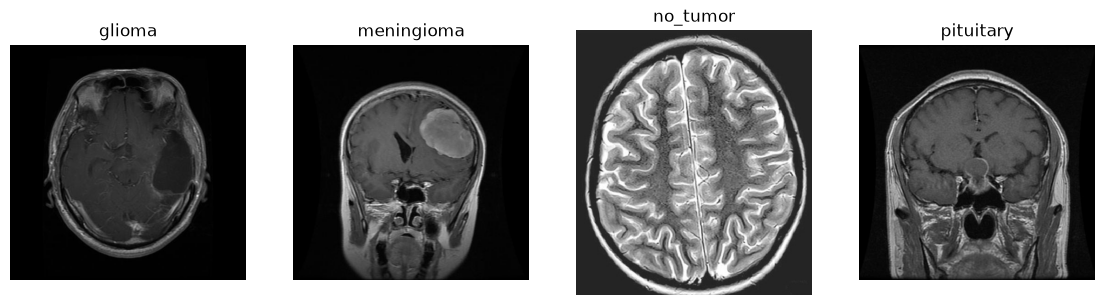

w    h  
512  512    3160
225  225      53
442  442      22
630  630      19
256  256      18
Name: count, dtype: int64


In [6]:
classes = sorted(df['label'].unique())
print('Classes:', classes)
print(df['label'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', order=classes)
plt.title('Images per class (after cleaning)')
plt.show()

fig, axes = plt.subplots(1, len(classes), figsize=(14, 4))
for ax, cls in zip(axes, classes):
    sample_path = df[df['label'] == cls].sample(1, random_state=SEED)['path'].values[0]
    ax.imshow(Image.open(sample_path), cmap='gray')
    ax.set_title(cls)
    ax.axis('off')
plt.show()

print(df[['w', 'h']].value_counts().head())   # original sizes (we resize to 224x224 later)

### 1.4 Répartition Train / Validation / Test (70 / 15 / 15)

Le dataset officiel contient déjà Train et Val, mais pas de Test, et ses proportions ne sont pas 70/15/15.
On **fusionne** les images propres (sans doublons), puis on re-divise avec `stratify` pour garder les mêmes proportions de classes dans chaque ensemble.

Train: 2599
Valid: 557
Test : 558


,Train,Valid,Test
label,,,
glioma,833,178,179
meningioma,761,163,163
pituitary,718,154,154
no_tumor,287,62,62


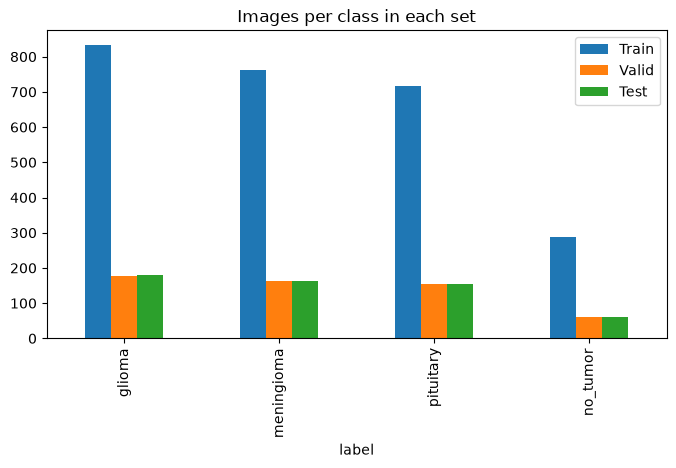

In [7]:
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=SEED
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)

print('Train:', len(train_df))
print('Valid:', len(valid_df))
print('Test :', len(test_df))

counts = pd.DataFrame({
    'Train': train_df['label'].value_counts(),
    'Valid': valid_df['label'].value_counts(),
    'Test': test_df['label'].value_counts(),
})
display(counts)

counts.plot(kind='bar', figsize=(8, 4), title='Images per class in each set')
plt.show()

### 1.5 Copie dans `data/split/`


In [8]:
assert SPLIT_DIR.name == 'split'            # safety: we only ever delete the generated folder
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)


def copy_files(dataframe, set_name):
    for _, row in dataframe.iterrows():
        dest = SPLIT_DIR / set_name / row['label']
        dest.mkdir(parents=True, exist_ok=True)
        # source prefix avoids name clashes between the Train and Val folders
        shutil.copy(row['path'], dest / f"{row['source']}_{Path(row['path']).name}")


copy_files(train_df, 'train')
copy_files(valid_df, 'val')
copy_files(test_df, 'test')

# keep a record of which image went where (traceability)
pd.concat([train_df.assign(set='train'), valid_df.assign(set='val'), test_df.assign(set='test')]) \
  .to_csv(DATA_DIR / 'split_manifest.csv', index=False)

print('Copy done ->', SPLIT_DIR)

Copy done -> c:\BrainScan_V2\data\split


### 1.6 Augmentation des données (train uniquement)

Val et Test ne sont **jamais** augmentés : ils simulent des données réelles jamais vues.

In [9]:
def blur(img):
    return cv2.GaussianBlur(img, (5, 5), 0)


def add_noise(img):
    noise = np.random.normal(0, 15, img.shape)
    noisy = img.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def flip(img):
    return cv2.flip(img, 1)

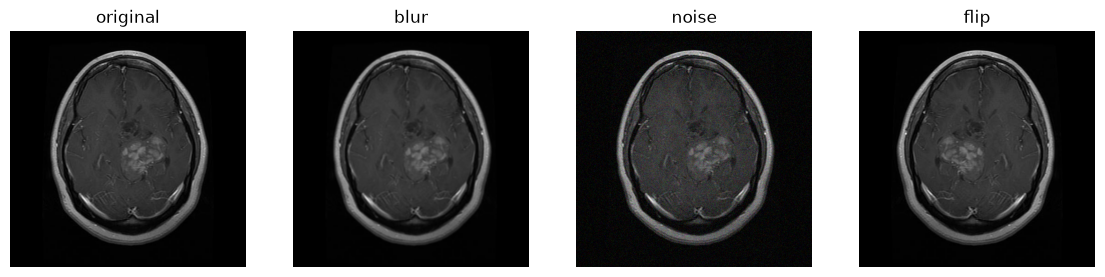

In [10]:
sample = next((SPLIT_DIR / 'train' / 'glioma').glob('*'))
img = cv2.imread(str(sample))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV reads BGR, matplotlib expects RGB

versions = {'original': img, 'blur': blur(img), 'noise': add_noise(img), 'flip': flip(img)}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, im) in zip(axes, versions.items()):
    ax.imshow(im)
    ax.set_title(name)
    ax.axis('off')
plt.show()

In [11]:
random.seed(SEED)
np.random.seed(SEED)

augmentations = {'blur': blur, 'flip': flip, 'noise': add_noise}

TRAIN_DIR = SPLIT_DIR / 'train'

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
target = max(class_counts.values())
print('Before:', class_counts, '-> target:', target)

for class_name, count in class_counts.items():
    class_dir = TRAIN_DIR / class_name
    originals = [f for f in class_dir.glob('*') if not f.name.startswith('aug_')]
    n_missing = target - count

    for i in range(n_missing):
        src = random.choice(originals)
        aug_name, aug_func = random.choice(list(augmentations.items()))

        img = cv2.imread(str(src))
        new_img = aug_func(img)

        new_path = class_dir / f'aug_{i}_{aug_name}_{src.name}'
        cv2.imwrite(str(new_path), new_img)

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
print('After: ', class_counts)

Before: {'glioma': 833, 'meningioma': 761, 'no_tumor': 287, 'pituitary': 718} -> target: 833
After:  {'glioma': 833, 'meningioma': 833, 'no_tumor': 833, 'pituitary': 833}


### 1.7 Pipeline `tf.data` : chargement, batch, normalisation

In [12]:
import tensorflow as tf

BATCH_SIZE = 32


def load_ds(folder, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        str(SPLIT_DIR / folder),
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        shuffle=shuffle,
        seed=SEED,
    )


train_ds = load_ds('train', shuffle=True)
val_ds = load_ds('val', shuffle=False)
test_ds = load_ds('test', shuffle=False)

class_names = train_ds.class_names
print(class_names)

Found 3332 files belonging to 4 classes.
Found 557 files belonging to 4 classes.
Found 558 files belonging to 4 classes.
['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [13]:
def normalize(x, y):
    return (tf.cast(x, tf.float32) / 127.5) - 1.0, y   # [0, 255] -> [-1, 1]


AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# check one batch
for images, labels in train_ds.take(1):
    print(images.shape, labels.shape)
    print('min/max:', images.numpy().min(), images.numpy().max())

(32, 224, 224, 3) (32, 4)
min/max: -1.0 1.0


In [15]:
from tensorflow.keras import models, layers 

NUM_CLASSES = len(class_names)

base_model = tf.keras.applications.InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=['accuracy']
)

model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [16]:
import time

feature_extractor = tf.keras.Sequential([base_model, layers.GlobalAveragePooling2D()])
FEATURES_FILE = DATA_DIR / 'features_inceptionv3.npz'


def count_files(folder):
    return sum(1 for f in (SPLIT_DIR / folder).rglob('*') if f.is_file())


def extract_features(ds):
    feats, labs = [], []
    for x, y in ds:                                           # features and labels come from the same batch,
        feats.append(feature_extractor.predict_on_batch(x))   # so they stay aligned even if ds is shuffled
        labs.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labs)


def cache_matches(npz):
    return all(len(npz[f'y_{s}']) == count_files(s) for s in ('train', 'val', 'test'))


if FEATURES_FILE.exists() and cache_matches(np.load(FEATURES_FILE)):
    data = np.load(FEATURES_FILE)
    X_train, y_train = data['X_train'], data['y_train']
    X_val, y_val = data['X_val'], data['y_val']
    X_test, y_test = data['X_test'], data['y_test']
    print('Features loaded from', FEATURES_FILE.name)
else:
    t0 = time.time()
    X_train, y_train = extract_features(train_ds)
    X_val, y_val = extract_features(val_ds)
    X_test, y_test = extract_features(test_ds)
    np.savez_compressed(FEATURES_FILE, X_train=X_train, y_train=y_train,
                        X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
    print(f'Features extracted and saved in {time.time() - t0:.0f}s')

print('train:', X_train.shape, y_train.shape)
print('val:  ', X_val.shape, y_val.shape)
print('test: ', X_test.shape, y_test.shape)

Features extracted and saved in 200s
train: (3332, 2048) (3332, 4)
val:   (557, 2048) (557, 4)
test:  (558, 2048) (558, 4)


,config,best_epoch,train_acc,val_acc,val_loss
0,adam_lr1e-3,20,0.9211,0.8923,0.3298
1,adam_lr1e-4,20,0.8382,0.8384,0.4340
2,sgd_lr1e-2_mom0.9,17,0.8649,0.8707,0.5921
3,adam_lr1e-2,1,0.7302,0.7289,0.7856


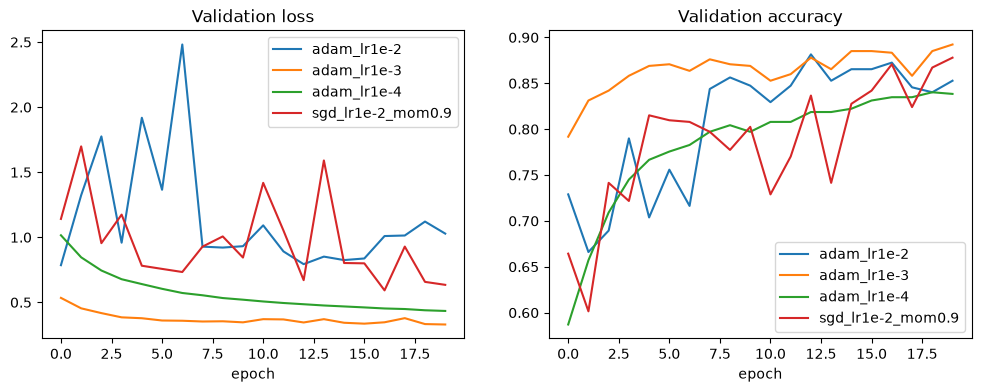

In [17]:
def build_head(optimizer):
    head = models.Sequential([
        layers.Input(shape=(2048,)),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ])
    head.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return head


configs = {
    'adam_lr1e-2': lambda: tf.keras.optimizers.Adam(1e-2),
    'adam_lr1e-3': lambda: tf.keras.optimizers.Adam(1e-3),
    'adam_lr1e-4': lambda: tf.keras.optimizers.Adam(1e-4),
    'sgd_lr1e-2_mom0.9': lambda: tf.keras.optimizers.SGD(1e-2, momentum=0.9),
}

EPOCHS_SEARCH = 20
results, histories = [], {}

for name, make_optimizer in configs.items():
    tf.keras.utils.set_random_seed(SEED)          # same start for every config = fair comparison
    head = build_head(make_optimizer())
    h = head.fit(X_train, y_train, validation_data=(X_val, y_val),
                 epochs=EPOCHS_SEARCH, batch_size=32, verbose=0)
    histories[name] = h.history
    best = int(np.argmin(h.history['val_loss']))
    results.append({
        'config': name,
        'best_epoch': best + 1,
        'train_acc': h.history['accuracy'][best],
        'val_acc': h.history['val_accuracy'][best],
        'val_loss': h.history['val_loss'][best],
    })

results_df = pd.DataFrame(results).sort_values('val_loss').reset_index(drop=True)
display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, hist in histories.items():
    axes[0].plot(hist['val_loss'], label=name)
    axes[1].plot(hist['val_accuracy'], label=name)
axes[0].set_title('Validation loss')
axes[1].set_title('Validation accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend()
plt.show()

Adam with learning rate 1e-3 gave the lowest validation loss (0.330) and the highest
validation accuracy (0.892) among the 4 configurations tested. Learning rate 1e-2 was
unstable (best epoch = 1), 1e-4 learned too slowly, and SGD with momentum converged more
slowly than Adam. The gap between train accuracy (0.921) and validation accuracy (0.892)
is small, so overfitting is limited. Loss: categorical cross-entropy, because labels are
one-hot over 4 mutually exclusive classes.

In [19]:
tf.keras.utils.set_random_seed(SEED)
head = build_head(tf.keras.optimizers.Adam(1e-3))

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)

history = head.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=32,
    callbacks=[early_stop]
)

hist = history.history
n_epochs = len(hist['loss'])
best_epoch = int(np.argmin(hist['val_loss'])) + 1
print(f"Stopped after {n_epochs} epochs | best epoch: {best_epoch}")
print(f"val_loss: {hist['val_loss'][best_epoch - 1]:.4f} | val_acc: {hist['val_accuracy'][best_epoch - 1]:.4f}")
print(f"train_acc: {hist['accuracy'][best_epoch - 1]:.4f}")

Epoch 1/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6624 - loss: 0.8418 - val_accuracy: 0.7917 - val_loss: 0.5344
Epoch 2/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7905 - loss: 0.5311 - val_accuracy: 0.8312 - val_loss: 0.4540
Epoch 3/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8268 - loss: 0.4443 - val_accuracy: 0.8420 - val_loss: 0.4173
Epoch 4/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8514 - loss: 0.3828 - val_accuracy: 0.8582 - val_loss: 0.3848
Epoch 5/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8664 - loss: 0.3498 - val_accuracy: 0.8689 - val_loss: 0.3779
Epoch 6/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8758 - loss: 0.3361 - val_accuracy: 0.8707 - val_loss: 0.3605
Epoch 7/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8866 - loss: 0.3116 - val_accuracy: 0.8636 - val_loss: 0.3587
Epoch 8/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8830 - loss: 0.2980 - val_accu

In [20]:
from sklearn.metrics import classification_report, accuracy_score


def evaluate_head(model_head, X, y_onehot, set_name):
    y_true = y_onehot.argmax(axis=1)                           # one-hot [0,0,1,0] -> class number 2
    y_pred = model_head.predict(X, verbose=0).argmax(axis=1)   # [0.05,0.1,0.8,0.05] -> class number 2
    print(f"=== {set_name} ===")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(classification_report(y_true, y_pred, labels=range(len(class_names)),
                                target_names=class_names, digits=4))
    return y_true, y_pred


y_true_test, y_pred_test = evaluate_head(head, X_test, y_test, 'TEST')

=== TEST ===
Accuracy: 0.8656
              precision    recall  f1-score   support

      glioma     0.8916    0.8268    0.8580       179
  meningioma     0.7637    0.8528    0.8058       163
    no_tumor     0.9048    0.9194    0.9120        62
   pituitary     0.9456    0.9026    0.9236       154

    accuracy                         0.8656       558
   macro avg     0.8764    0.8754    0.8748       558
weighted avg     0.8706    0.8656    0.8668       558



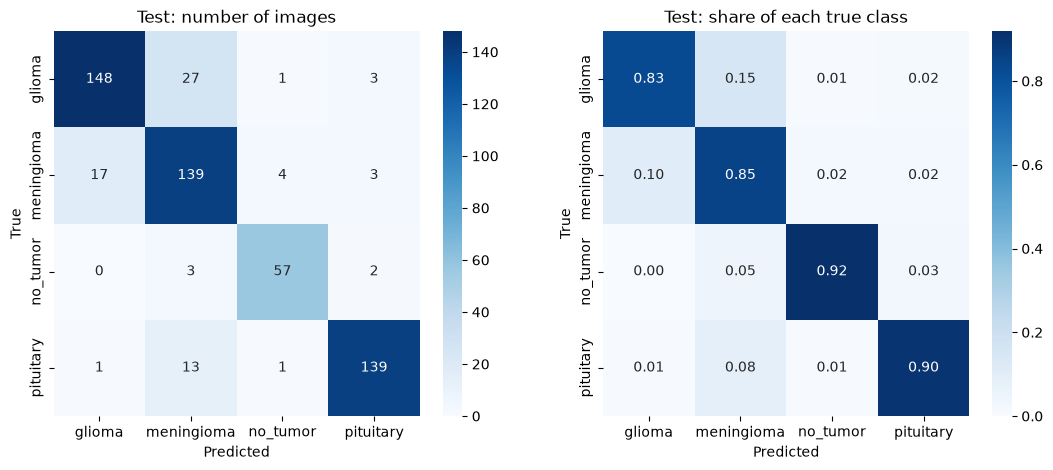

In [21]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

labels = range(len(class_names))
cm = confusion_matrix(y_true_test, y_pred_test, labels=labels)
cm_pct = confusion_matrix(y_true_test, y_pred_test, labels=labels, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Test: number of images')
sns.heatmap(cm_pct, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Test: share of each true class')
for ax in axes:
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.show()

In [22]:
rows = []
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    yt = y.argmax(axis=1)
    yp = head.predict(X, verbose=0).argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    rows.append({'set': name, 'accuracy': accuracy_score(yt, yp),
                 'precision': p, 'recall': r, 'f1': f1})

compare_df = pd.DataFrame(rows).set_index('set')
display(compare_df.round(4))

,accuracy,precision,recall,f1
set,,,,
train,0.9661,0.9660,0.9661,0.9660
val,0.8923,0.8957,0.8968,0.8960
test,0.8656,0.8764,0.8754,0.8748
